# Example 7.3 — Bi-objective Optimization: Pareto Front

**Chapter 7: Hybrid and Advanced Strategies**

Simultaneously optimize the Hausdorff distance and the minimum transmission angle using a multi-objective GA (simplified NSGA-II) with only `numpy`.

**Book Reference:** Section 7.3 — Multi-Objective Optimization with Pareto Front

In [1]:
import builtins
from numpy import *

# ── Mechanism functions ────────────────────────────────────────────
THETA2 = linspace(0, 2 * pi, 60)
TARGET = column_stack([40 * cos(THETA2), 20 * sin(THETA2)])

def analizar(a, b, c, d=50.0):
    """Returns (coupler_points, transmission_angles)."""
    pts, mu_list = [], []
    for t2 in THETA2:
        K1 = d / a
        K2 = d / c
        K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)
        A = cos(t2) - K1 - K2 * cos(t2) + K3
        B = -2 * sin(t2)
        C = K1 - (K2 + 1) * cos(t2) + K3
        disc = B**2 - 4 * A * C
        if disc < 0 or abs(A) < 1e-9:
            continue
        t4 = 2 * arctan((-B - sqrt(disc)) / (2 * A))
        t3 = arctan2(a * sin(t2) - c * sin(t4), a * cos(t2) + d - c * cos(t4))
        pts.append((a * cos(t2) + b * cos(t3), a * sin(t2) + b * sin(t3)))
        mu = degrees(t3 - t4)
        mu_list.append(mu)
    return (
        array(pts) if pts else zeros((1, 2)),
        array(mu_list) if mu_list else array([0.0])
    )

def hausdorff(P, Q):
    if len(P) < 2 or len(Q) < 2:
        return 1e6
    n = builtins.min(len(P), len(Q))
    P, Q = P[:n], Q[:n]
    d1 = builtins.max(builtins.min(sqrt(sum((p - q)**2)) for q in Q) for p in P)
    d2 = builtins.max(builtins.min(sqrt(sum((p - q)**2)) for p in P) for q in Q)
    return builtins.max(d1, d2)

def objectives(ind):
    a, b, c = ind
    if a <= 0 or b <= 0 or c <= 0:
        return 1e6, -999
    pts, mu = analizar(a, b, c)
    f1 = hausdorff(pts, TARGET)  # minimize
    f2 = mu.min()                 # maximize → minimize -f2
    return f1, f2

print('Objective functions defined:')
print('  f1: Hausdorff Distance (minimize)')
print('  f2: Minimum transmission angle (maximize)')

Objective functions defined:
  f1: Hausdorff Distance (minimize)
  f2: Minimum transmission angle (maximize)


In [2]:
# ── Pareto dominance ───────────────────────────────────────────────
def dominates(f_a, f_b):
    """Returns True if f_a dominates f_b (min f1, max f2 → min -f2)."""
    # f1 minimize, f2 maximize
    better_or_equal = (f_a[0] <= f_b[0]) and (f_a[1] >= f_b[1])
    strictly_better = (f_a[0] < f_b[0]) or (f_a[1] > f_b[1])
    return better_or_equal and strictly_better

def pareto_front(F):
    """Returns boolean mask of non-dominated solutions."""
    n = len(F)
    mask = ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        for j in range(n):
            if i == j or not mask[j]:
                continue
            if dominates(F[j], F[i]):
                mask[i] = False
                break
    return mask

# ── Multi-objective GA (random population + Pareto filter) ──────────
random.seed(0)
N = 120
pop = random.uniform(10, 100, (N, 3))
F = array([objectives(ind) for ind in pop])
pareto_mask = pareto_front(F)
pareto_pts = pop[pareto_mask]
pareto_F = F[pareto_mask]

print(f'Total solutions: {N}')
print(f'Pareto Front:    {pareto_mask.sum()} points')
print('\nTop-5 of the Pareto front:')

idx_sort = argsort(pareto_F[:, 0])
for k, i in enumerate(idx_sort[:5]):
    a, b, c = pareto_pts[i]
    f1, f2 = pareto_F[i]
    print(f'  {k+1}. a={a:.1f}, b={b:.1f}, c={c:.1f} → H={f1:.1f}mm, μ={f2:.1f}°')

Total solutions: 120
Pareto Front:    7 points

Top-5 of the Pareto front:
  1. a=14.9, b=28.0, c=11.7 → H=33.9mm, μ=-184.9°
  2. a=12.2, b=16.1, c=71.1 → H=36.8mm, μ=-184.1°
  3. a=65.6, b=11.2, c=41.3 → H=52.4mm, μ=-83.7°
  4. a=87.0, b=11.1, c=42.4 → H=75.4mm, μ=-45.2°
  5. a=96.6, b=36.3, c=31.7 → H=115.7mm, μ=-23.8°


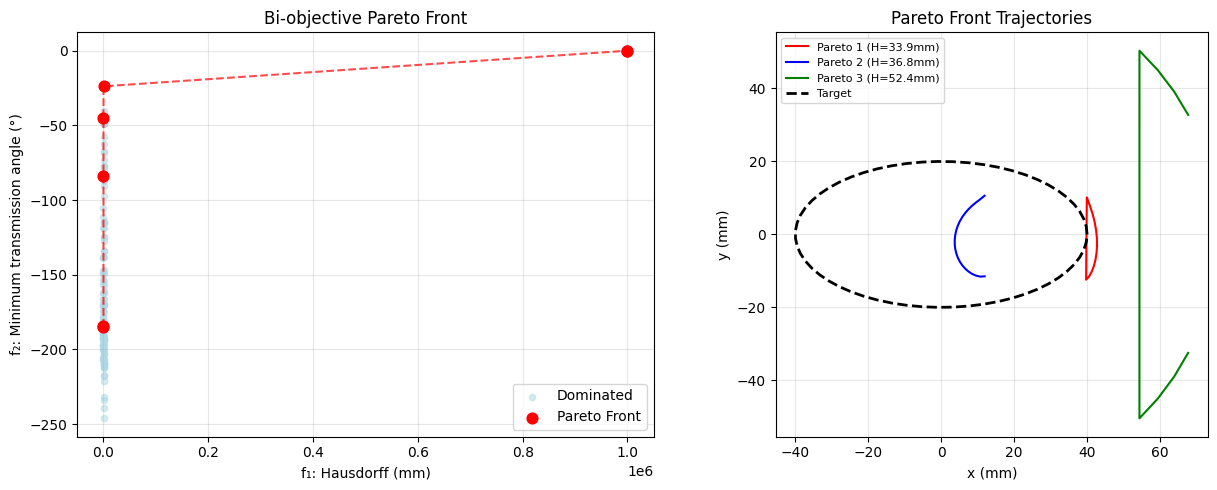

In [3]:
# ── Pareto Front Visualization ────────────────────────────────
import matplotlib.pyplot as plt
from numpy import argsort

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Target space
ax = axes[0]
ax.scatter(
    F[~pareto_mask, 0], F[~pareto_mask, 1],
    c='lightblue', s=20, alpha=0.5, label='Dominated'
)
ax.scatter(
    pareto_F[:, 0], pareto_F[:, 1],
    c='red', s=60, zorder=5, label='Pareto Front'
)

# Front line
sorted_idx = argsort(pareto_F[:, 0])
ax.plot(
    pareto_F[sorted_idx, 0], pareto_F[sorted_idx, 1],
    'r--', alpha=0.7
)
ax.set_xlabel('f₁: Hausdorff (mm)')
ax.set_ylabel('f₂: Minimum transmission angle (°)')
ax.set_title('Bi-objective Pareto Front')
ax.legend()
ax.grid(True, alpha=0.3)

# Trajectories of the 3 best Pareto solutions
ax = axes[1]
colors = ['red', 'blue', 'green']
for k, i in enumerate(idx_sort[:3]):
    pts, _ = analizar(*pareto_pts[i])
    ax.plot(
        pts[:, 0], pts[:, 1], color=colors[k], lw=1.5,
        label=f'Pareto {k+1} (H={pareto_F[i, 0]:.1f}mm)'
)
ax.plot(TARGET[:, 0], TARGET[:, 1], 'k--', lw=2, label='Target')
ax.set_aspect('equal')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_title('Pareto Front Trajectories')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()